# Session 3: Introduction to Functions

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in []:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-03_define_call.py`

In [2]:
"""
Session 3 · Example 1: defining, calling and returning
------------------------------------------------------
Run:  python session-03_define_call.py
"""
import math

# 1. Built-in functions are always available
marks = [78, 91, 64, 85]
print("built-ins:", len(marks), max(marks), min(marks), sum(marks), round(sum(marks) / len(marks), 1))
# Functions from a module need an import
print("math module:", math.sqrt(144), math.ceil(4.1), round(math.pi, 4))

# 2. A user-defined function: def, name, parameters, colon, indented body
def greet(name):
    """Return a greeting for one person."""
    return f"Assalam-o-Alaikum, {name}!"

print(greet("Ayesha"))            # call it with an argument

# 3. A function with no return statement returns None
def show_line(width):
    print("-" * width)

result = show_line(20)
print("show_line returned:", result)

# 4. Returning several values (really a tuple) and unpacking them
def stats(values):
    """Return mean, min and max of a list of numbers."""
    mean = sum(values) / len(values)
    return mean, min(values), max(values)

avg, low, high = stats(marks)
print(f"mean {avg:.2f}, lowest {low}, highest {high}")
print("raw return value:", stats(marks))

# 5. return ends the function early (guard clauses)
def safe_divide(a, b):
    if b == 0:
        return None               # leave immediately, skip the rest
    return a / b
print("safe_divide:", safe_divide(10, 4), safe_divide(1, 0))

# 6. Functions are objects: store them, pass them, return them
def square(x): return x * x
def cube(x): return x ** 3
operations = {"square": square, "cube": cube}
for name, fn in operations.items():
    print(f"{name}(4) = {fn(4)}")

def apply_to_all(fn, values):
    return [fn(v) for v in values]
print("apply_to_all(square):", apply_to_all(square, [1, 2, 3]))

# 7. Type hints and docstrings document the contract (not enforced at runtime)
def bmi(weight_kg: float, height_m: float) -> float:
    """Body-mass index = weight / height squared, rounded to 1 decimal."""
    return round(weight_kg / height_m ** 2, 1)
print("bmi(68, 1.72) =", bmi(68, 1.72), "| hints:", bmi.__annotations__)
help(bmi)

built-ins: 4 91 64 318 79.5
math module: 12.0 5 3.1416
Assalam-o-Alaikum, Ayesha!
--------------------
show_line returned: None
mean 79.50, lowest 64, highest 91
raw return value: (79.5, 64, 91)
safe_divide: 2.5 None
square(4) = 16
cube(4) = 64
apply_to_all(square): [1, 4, 9]
bmi(68, 1.72) = 23.0 | hints: {'weight_kg': <class 'float'>, 'height_m': <class 'float'>, 'return': <class 'float'>}
Help on function bmi in module __main__:

bmi(weight_kg: float, height_m: float) -> float
    Body-mass index = weight / height squared, rounded to 1 decimal.



## Example: `session-03_scope.py`

In [3]:
"""
Session 3 · Example 2: variable scope (LEGB) with global and nonlocal
---------------------------------------------------------------------
Run:  python session-03_scope.py
"""
course = "Diploma in AI"            # Global scope: defined at module level

def show_course():
    print("inside, reading the global:", course)      # reading is allowed

def local_demo():
    course = "local copy"           # Local: a NEW variable, hides the global
    print("inside, local:", course)

show_course(); local_demo()
print("outside, global unchanged:", course)

# Assigning to a name anywhere in a function makes it local for the WHOLE function
def broken():
    try:
        print(counter)              # Python already decided 'counter' is local
        counter = 1
    except UnboundLocalError as e:
        print("UnboundLocalError:", e)
counter = 0
broken()

# global lets a function rebind a module-level name (use sparingly)
visits = 0
def record_visit():
    global visits
    visits += 1
for _ in range(3):
    record_visit()
print("visits after 3 calls:", visits)

# Enclosing scope and nonlocal: a closure that remembers state
def make_counter(start=0):
    count = start                   # Enclosing scope for the inner function
    def increment(step=1):
        nonlocal count              # rebind the enclosing variable
        count += step
        return count
    return increment

ticket = make_counter(100)
print("tickets:", ticket(), ticket(), ticket(5))
other = make_counter()
print("independent counter:", other(), "| first counter still at:", ticket(0))

# Built-in scope: names like len and print live here; shadowing them is legal but risky
def shadow_demo():
    len = 5                         # local 'len' hides the built-in
    return len
print("shadow_demo():", shadow_demo(), "| built-in len still works outside:", len("abc"))

# LEGB lookup order demonstrated with one name defined at three levels
x = "global x"
def outer():
    x = "enclosing x"
    def inner():
        x = "local x"
        return x
    return inner(), x
print("LEGB:", outer(), "|", x)

inside, reading the global: Diploma in AI
inside, local: local copy
outside, global unchanged: Diploma in AI
UnboundLocalError: cannot access local variable 'counter' where it is not associated with a value
visits after 3 calls: 3
tickets: 101 102 107
independent counter: 1 | first counter still at: 107
shadow_demo(): 5 | built-in len still works outside: 3
LEGB: ('local x', 'enclosing x') | global x


## Example: `session-03_arguments.py`

In [4]:
"""
Session 3 · Example 3: parameters and every kind of argument
------------------------------------------------------------
Run:  python session-03_arguments.py
"""
# Parameters are the names in the definition; arguments are the values in the call.
def order(item, qty, price):
    return f"{qty} x {item} @ Rs {price} = Rs {qty * price:,}"

print("positional:", order("biryani", 2, 450))                 # matched by position
print("keyword:   ", order(price=450, item="biryani", qty=2))  # matched by name
print("mixed:     ", order("chai", price=80, qty=3))           # positional first

# Default values make a parameter optional
def ticket_price(base, child=False, discount=0.0):
    price = base * (0.5 if child else 1)
    return round(price * (1 - discount))
print("defaults:", ticket_price(1200), ticket_price(1200, child=True), ticket_price(1200, discount=0.1))

# *args collects extra positional arguments into a tuple
def total(*amounts):
    print("  args tuple:", amounts)
    return sum(amounts)
print("*args:", total(100, 250, 75))

# **kwargs collects extra keyword arguments into a dict
def profile(name, **details):
    extras = ", ".join(f"{k}={v}" for k, v in details.items())
    return f"{name} ({extras})"
print("**kwargs:", profile("Hira", city="Karachi", cgpa=3.7, semester=2))

# Keyword-only (after *) and positional-only (before /) parameters
def transfer(amount, /, *, to_account, note=""):
    return f"Sent Rs {amount:,} to {to_account} {note}".strip()
print("kw-only:", transfer(5000, to_account="PK36-XXXX-0042", note="(rent)"))
try:
    transfer(5000, "PK36")                          # to_account must be given by name
except TypeError as e:
    print("  TypeError:", e)
try:
    transfer(amount=5000, to_account="PK36")        # amount must be given by position
except TypeError as e:
    print("  TypeError:", e)

# Unpacking a list/dict INTO arguments with * and **
args = ["samosa", 6, 40]
kwargs = {"item": "jalebi", "qty": 1, "price": 300}
print("unpack *:", order(*args), "| unpack **:", order(**kwargs))

# The mutable-default trap and its fix
def add_bad(item, basket=[]):          # the SAME list is reused on every call
    basket.append(item); return basket
def add_good(item, basket=None):
    if basket is None:
        basket = []                     # a fresh list each call
    basket.append(item); return basket
print("bad :", add_bad("milk"), add_bad("eggs"))
print("good:", add_good("milk"), add_good("eggs"))

# Arguments are passed by object reference: mutating a list inside is visible outside
def give_bonus(marks):
    for i in range(len(marks)):
        marks[i] += 5
scores = [60, 70]
give_bonus(scores)
print("after give_bonus:", scores)

positional: 2 x biryani @ Rs 450 = Rs 900
keyword:    2 x biryani @ Rs 450 = Rs 900
mixed:      3 x chai @ Rs 80 = Rs 240
defaults: 1200 600 1080
  args tuple: (100, 250, 75)
*args: 425
**kwargs: Hira (city=Karachi, cgpa=3.7, semester=2)
kw-only: Sent Rs 5,000 to PK36-XXXX-0042 (rent)
  TypeError: transfer() takes 1 positional argument but 2 were given
  TypeError: transfer() got some positional-only arguments passed as keyword arguments: 'amount'
unpack *: 6 x samosa @ Rs 40 = Rs 240 | unpack **: 1 x jalebi @ Rs 300 = Rs 300
bad : ['milk', 'eggs'] ['milk', 'eggs']
good: ['milk'] ['eggs']
after give_bonus: [65, 75]


## Example: `session-03_problem_payroll.py`

In [5]:
"""
Session 3 · Real-life problem: monthly salary slips
---------------------------------------------------
PROBLEM
An HR officer must produce salary slips. For each employee:
  gross = basic + house rent (45 % of basic) + medical (10 % of basic) + overtime
  overtime = hours x (basic / 208) x 1.5          (208 working hours a month)
  income tax uses the ILLUSTRATIVE annual slabs below (practice values only)
  provident fund = 8 % of basic
  net = gross - tax - provident fund
Write it as small, single-purpose functions with docstrings, default
arguments and keyword arguments, then print a slip per employee and a summary.
Run:  python session-03_problem_payroll.py
"""
TAX_SLABS = [        # (annual income up to, fixed tax, rate on the excess above the previous limit)
    (600_000, 0, 0.00),
    (1_200_000, 0, 0.05),
    (2_200_000, 30_000, 0.15),
    (3_200_000, 180_000, 0.25),
    (float("inf"), 430_000, 0.35),
]

def allowances(basic, house_pct=0.45, medical_pct=0.10):
    """Return (house rent, medical) allowances as a tuple."""
    return basic * house_pct, basic * medical_pct

def overtime_pay(basic, hours=0, rate=1.5, monthly_hours=208):
    """Overtime is paid at 1.5x the hourly rate by default."""
    return hours * (basic / monthly_hours) * rate

def annual_tax(income):
    """Apply the slab table to a yearly income."""
    lower = 0
    for upper, fixed, rate in TAX_SLABS:
        if income <= upper:
            return fixed + (income - lower) * rate
        lower = upper

def monthly_slip(name, basic, *, overtime_hours=0, pf_rate=0.08):
    """Build one salary slip as a dict. Keyword-only options avoid mix-ups."""
    house, medical = allowances(basic)
    ot = overtime_pay(basic, overtime_hours)
    gross = basic + house + medical + ot
    tax = annual_tax(gross * 12) / 12
    pf = basic * pf_rate
    return {"name": name, "basic": basic, "house": house, "medical": medical,
            "overtime": ot, "gross": gross, "tax": tax, "pf": pf, "net": gross - tax - pf}

def print_slip(slip):
    print(f"Salary slip: {slip['name']}")
    for key in ["basic", "house", "medical", "overtime", "gross", "tax", "pf", "net"]:
        sign = "-" if key in ("tax", "pf") else " "
        print(f"   {key:<9}{sign} Rs {slip[key]:>10,.0f}")
    print()

staff = [("Ahmed (lab engineer)", 60_000, 0), ("Fatima (lecturer)", 110_000, 0),
         ("Kamran (technician)", 45_000, 22), ("Zara (manager)", 210_000, 0)]
slips = [monthly_slip(n, b, overtime_hours=h) for n, b, h in staff]
for s in slips:
    print_slip(s)

def summary(slips):
    """Payroll totals and the effective tax rate per person."""
    print(f"{'Employee':22} {'Gross':>10} {'Tax':>9} {'Eff. tax':>8}")
    for s in slips:
        print(f"{s['name']:22} {s['gross']:>10,.0f} {s['tax']:>9,.0f} {s['tax'] / s['gross']:>8.1%}")
    print(f"{'TOTAL payroll cost':22} {sum(s['gross'] for s in slips):>10,.0f}")
summary(slips)

Salary slip: Ahmed (lab engineer)
   basic      Rs     60,000
   house      Rs     27,000
   medical    Rs      6,000
   overtime   Rs          0
   gross      Rs     93,000
   tax      - Rs      2,150
   pf       - Rs      4,800
   net        Rs     86,050

Salary slip: Fatima (lecturer)
   basic      Rs    110,000
   house      Rs     49,500
   medical    Rs     11,000
   overtime   Rs          0
   gross      Rs    170,500
   tax      - Rs     13,075
   pf       - Rs      8,800
   net        Rs    148,625

Salary slip: Kamran (technician)
   basic      Rs     45,000
   house      Rs     20,250
   medical    Rs      4,500
   overtime   Rs      7,139
   gross      Rs     76,889
   tax      - Rs      1,344
   pf       - Rs      3,600
   net        Rs     71,945

Salary slip: Zara (manager)
   basic      Rs    210,000
   house      Rs     94,500
   medical    Rs     21,000
   overtime   Rs          0
   gross      Rs    325,500
   tax      - Rs     56,425
   pf       - Rs     16,800
   

## Example: `session-03_project_loan_planner.py`

In [6]:
"""
Session 3 · Mini project: loan / instalment planner
---------------------------------------------------
A small library of functions that answers real questions about a loan:
  emi()        - fixed monthly instalment (standard reducing-balance formula)
  schedule()   - month-by-month split into interest and principal
  compare()    - total cost of several tenures
Each function does one job, has a docstring and sensible defaults.
Run:  python session-03_project_loan_planner.py
"""
def emi(principal, annual_rate, years):
    """Monthly instalment: P*r*(1+r)^n / ((1+r)^n - 1), r = monthly rate, n = months."""
    r = annual_rate / 12
    n = years * 12
    if r == 0:
        return principal / n
    growth = (1 + r) ** n
    return principal * r * growth / (growth - 1)

def schedule(principal, annual_rate, years):
    """Yield (month, interest, principal_paid, balance) for every month."""
    pay = emi(principal, annual_rate, years)
    balance = principal
    for month in range(1, years * 12 + 1):
        interest = balance * annual_rate / 12
        paid = pay - interest
        balance -= paid
        yield month, interest, paid, max(balance, 0)

def compare(principal, annual_rate, tenures=(1, 2, 3, 5)):
    """Return a list of dicts comparing instalment and total interest by tenure."""
    rows = []
    for years in tenures:
        m = emi(principal, annual_rate, years)
        rows.append({"years": years, "emi": m, "total": m * years * 12,
                     "interest": m * years * 12 - principal})
    return rows

LOAN, RATE = 1_500_000, 0.18          # e.g. a used-car loan at 18 % a year
print(f"Loan Rs {LOAN:,} at {RATE:.0%} a year")
print(f"{'Years':>5} {'EMI':>10} {'Total paid':>12} {'Interest':>11}")
for row in compare(LOAN, RATE):
    print(f"{row['years']:>5} {row['emi']:>10,.0f} {row['total']:>12,.0f} {row['interest']:>11,.0f}")

print("\nFirst and last months of the 3-year plan")
rows = list(schedule(LOAN, RATE, 3))
for month, interest, paid, bal in rows[:3] + rows[-2:]:
    print(f"  month {month:>2}: interest {interest:>8,.0f}  principal {paid:>8,.0f}  balance {bal:>10,.0f}")

# Chart: how each instalment is split over time
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
months = [r[0] for r in rows]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.stackplot(months, [r[2] for r in rows], [r[1] for r in rows],
             labels=["Principal part", "Interest part"], colors=["#FF6B1A", "#A78BFA"])
ax.set_xlabel("Month"); ax.set_ylabel("Rs per instalment")
ax.set_title("Same instalment every month, but the interest share shrinks")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig("session-03_project_loan_planner.png", dpi=110)
print("Chart saved: session-03_project_loan_planner.png")

Loan Rs 1,500,000 at 18% a year
Years        EMI   Total paid    Interest
    1    137,520    1,650,240     150,240
    2     74,886    1,797,268     297,268
    3     54,229    1,952,229     452,229
    5     38,090    2,285,408     785,408

First and last months of the 3-year plan
  month  1: interest   22,500  principal   31,729  balance  1,468,271
  month  2: interest   22,024  principal   32,205  balance  1,436,067
  month  3: interest   21,541  principal   32,688  balance  1,403,379
  month 35: interest    1,591  principal   52,638  balance     53,427
  month 36: interest      801  principal   53,427  balance          0


Chart saved: session-03_project_loan_planner.png


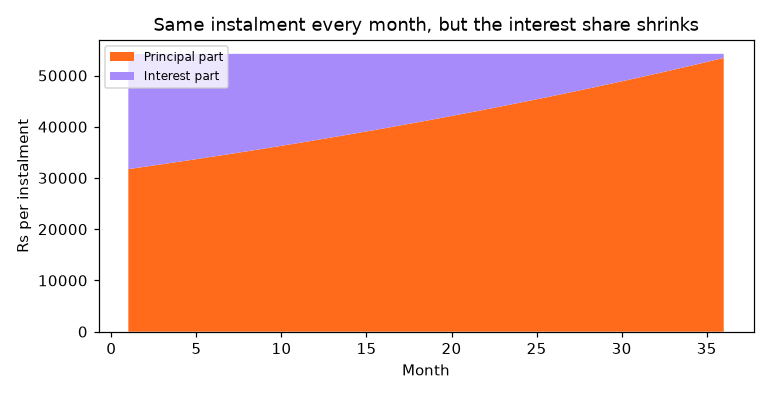

In [7]:
from IPython.display import Image, display
display(Image(filename='session-03_project_loan_planner.png'))  # chart saved by the cell above